# PM2.5 Forecasting — Data Exploration and Preprocessing (Gradient Boosting)

**Group model:** G7 — Gradient Boosting  
**Preparation assumption:** one-day-ahead forecasting. If the instructor/group selects another horizon, regenerate the lag features accordingly.

This notebook continues the EDA and prepares past-only features. It does **not** train the final model yet. The project deadline for exploration and preprocessing is 14 November 2026; model training/evaluation is due 12 December 2026.

## Workflow
1. Load and validate the cleaned data.
2. Inspect station/date coverage and temporal gaps.
3. Create `Exploratory_temporal.csv`.
4. Build one-day-ahead features using only information from the previous calendar day.
5. Keep missing values for fold-specific imputation later; do not impute on the full dataset.
6. Prepare the chronological validation strategy.

In [6]:
from google.colab import files
uploaded = files.upload()
input_file = next(iter(uploaded))
print("Uploaded file:", input_file)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json, warnings
from scipy.stats import linregress, ks_2samp
from statsmodels.tsa.stattools import pacf, adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox

df = pd.read_csv(input_file)
df["date"] = pd.to_datetime(df["date"], errors="coerce").dt.normalize()
df = df.dropna(subset=["date", "id", "pm25"]).sort_values(["id", "date"]).copy()

print("Shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Stations:", df["id"].nunique())
print("Duplicate (date, id):", df.duplicated(["date", "id"]).sum())
display(df.head())

Saving PM25_Cleaned.csv to PM25_Cleaned (1).csv
Uploaded file: PM25_Cleaned (1).csv
Shape: (40983, 15)
Date range: 2016-11-25 00:00:00 to 2026-04-06 00:00:00
Stations: 95
Duplicate (date, id): 0


,date,datetime_utc,id,latitude,longitude,temperature_celsius,pressure_mb,wind_u,wind_v,NO2,CO,O3,AOD,pm25,sensor_name
36,2016-12-07,2016-12-07 00:00:00,0,38.454722,-0.803333,9.768313,965.439025,-0.523074,-1.949791,NaN,NaN,NaN,0.144000,12.111111,ELDA-LACY
60,2016-12-11,2016-12-11 00:00:00,0,38.454722,-0.803333,10.490162,961.187736,0.494681,-0.604369,NaN,NaN,NaN,0.043000,16.062500,ELDA-LACY
73,2016-12-12,2016-12-12 00:00:00,0,38.454722,-0.803333,8.648906,959.161696,0.779160,-1.136173,NaN,NaN,NaN,0.044333,12.571429,ELDA-LACY
98,2016-12-14,2016-12-14 00:00:00,0,38.454722,-0.803333,8.881884,958.157611,0.342758,0.317658,NaN,NaN,NaN,0.217000,21.666667,ELDA-LACY
111,2017-01-05,2017-01-05 00:00:00,0,38.454722,-0.803333,8.841884,958.807323,0.559532,-1.164098,NaN,NaN,NaN,0.046000,11.400000,ELDA-LACY


## Step 1 — Check the station metadata

The protocol asks us to verify station identifiers and coordinates. We check whether each `id` has stable coordinates and whether station-date records are duplicated. IDs are grouping keys, not predictive features for spatial validation.

In [7]:
station_check = df.groupby("id").agg(
    n_records=("pm25", "size"),
    n_latitudes=("latitude", "nunique"),
    n_longitudes=("longitude", "nunique"),
    n_sensor_names=("sensor_name", "nunique"),
    first_date=("date", "min"),
    last_date=("date", "max")
)
display(station_check.describe(include="all"))
print("IDs with changing coordinates:",
      ((station_check["n_latitudes"] > 1) | (station_check["n_longitudes"] > 1)).sum())

,n_records,n_latitudes,n_longitudes,n_sensor_names,first_date,last_date
count,95.000000,95.0,95.0,95.0,95,95
mean,431.400000,1.0,1.0,1.0,2022-04-22 20:27:47.368421120,2025-01-21 12:53:03.157894656
min,4.000000,1.0,1.0,1.0,2016-11-25 00:00:00,2019-09-01 00:00:00
25%,205.500000,1.0,1.0,1.0,2021-03-09 00:00:00,2024-08-28 00:00:00
50%,442.000000,1.0,1.0,1.0,2023-04-01 00:00:00,2025-10-23 00:00:00
75%,646.500000,1.0,1.0,1.0,2024-08-31 00:00:00,2026-04-06 00:00:00
max,1042.000000,1.0,1.0,1.0,2026-04-03 00:00:00,2026-04-06 00:00:00
std,266.997227,0.0,0.0,0.0,NaN,NaN


IDs with changing coordinates: 0


## Step 2 — Build station-level temporal diagnostics

For each station we:
- reindex PM2.5 to a daily calendar to reveal missing dates;
- calculate median and standard deviation of observed sampling intervals;
- calculate ACF at lags 1 and 7 on the daily-indexed series;
- calculate PACF, Ljung–Box, ADF and KPSS only on the longest uninterrupted daily segment (minimum 30 observations);
- calculate a linear trend, monthly-median seasonal amplitude and a KS drift diagnostic.

**Important:** a missing diagnostic is not zero. It means the available uninterrupted data were insufficient or the test could not be calculated. Daily data do not support a diurnal amplitude, so that field remains empty.

In [8]:
temporal_rows = []
for sid, g in df.groupby("id", sort=True):
    g = g.sort_values("date")
    s = g.set_index("date")["pm25"].asfreq("D")
    observed = s.dropna()
    n = len(observed)
    start, end = observed.index.min(), observed.index.max()
    span_days = (end - start).days + 1
    missing_days = max(span_days - n, 0)
    intervals = observed.index.to_series().diff().dt.total_seconds().dropna()

    acf1 = float(s.autocorr(1)) if n > 2 else np.nan
    acf7 = float(s.autocorr(7)) if n > 8 else np.nan

    mask = s.notna().to_numpy()
    best_start = best_len = run_start = run_len = 0
    for i, present in enumerate(mask):
        if present:
            if run_len == 0: run_start = i
            run_len += 1
            if run_len > best_len: best_start, best_len = run_start, run_len
        else:
            run_len = 0
    contiguous = s.iloc[best_start:best_start + best_len].dropna().to_numpy(dtype=float)

    pacf1 = lb_p = adf_p = kpss_p = np.nan
    if len(contiguous) >= 30:
        try: pacf1 = float(pacf(contiguous, nlags=1, method="ywm")[1])
        except Exception: pass
        try:
            lb_lag = min(7, max(1, len(contiguous)//5))
            lb_p = float(acorr_ljungbox(contiguous, lags=[lb_lag], return_df=True)["lb_pvalue"].iloc[0])
        except Exception: pass
        try: adf_p = float(adfuller(contiguous, autolag="AIC")[1])
        except Exception: pass
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                kpss_p = float(kpss(contiguous, regression="c", nlags="auto")[1])
        except Exception: pass

    x = (observed.index - observed.index.min()).days.to_numpy()
    if n >= 3:
        tr = linregress(x, observed.to_numpy())
        slope, trend_p = float(tr.slope), float(tr.pvalue)
    else:
        slope = trend_p = np.nan

    monthly = observed.resample("MS").median().dropna()
    seasonal_amp = float(monthly.max()-monthly.min()) if monthly.index.to_period("M").nunique() >= 12 else np.nan
    mid = n//2
    if mid >= 10 and n-mid >= 10:
        drift = ks_2samp(observed.iloc[:mid], observed.iloc[mid:])
        drift_stat, drift_p = float(drift.statistic), float(drift.pvalue)
    else:
        drift_stat = drift_p = np.nan

    full_index = pd.date_range(start, end, freq="D")
    expanded = g.set_index("date").reindex(full_index)
    monthly_missing = {}
    for col, key in [("NO2","no2"),("CO","co"),("O3","o3")]:
        mm = (expanded[col].isna().resample("MS").mean()*100).dropna()
        monthly_missing[key] = json.dumps({str(k.to_period("M")): round(float(v),2) for k,v in mm.items()})

    above25 = int((observed > 25).sum())
    above50 = int((observed > 50).sum())
    temporal_rows.append({
        "model_id":"gradient_boosting_pm25", "model_group":"G7", "variable":"pm25",
        "node_id":str(sid), "n_records":n, "t_min":start, "t_max":end,
        "sampling_interval_median_sec":intervals.median(),
        "sampling_interval_std_sec":intervals.std(),
        "pct_missing_intervals":missing_days/(span_days-1)*100 if span_days>1 else 0,
        "acf_lag1":acf1, "acf_lag7":acf7, "acf_lag24":np.nan, "pacf_lag1":pacf1,
        "ljung_box_p":lb_p, "adf_p":adf_p, "kpss_p":kpss_p,
        "trend_slope_per_day":slope, "trend_pval":trend_p,
        "diurnal_amplitude":np.nan, "seasonal_amplitude":seasonal_amp,
        "target_drift_stat":drift_stat, "target_drift_pval":drift_p,
        "n_days_above_25":above25, "n_days_above_50":above50,
        "pct_days_above_25":above25/n*100, "pct_days_above_50":above50/n*100,
        "regime_breaks":np.nan, "cv_strategy_recommended":"temporal+spatial",
        "gap_between_train_test_sec":86400, "n_cycles_observed":observed.index.year.nunique(),
        "no2_pct_missing_by_month":monthly_missing["no2"],
        "co_pct_missing_by_month":monthly_missing["co"],
        "o3_pct_missing_by_month":monthly_missing["o3"],
        "notes":f"Longest uninterrupted daily segment={len(contiguous)}; ACF uses daily-indexed aligned pairs; tests use longest uninterrupted segment; diurnal amplitude not applicable; n_cycles_observed counts years represented, not complete cycles."
    })

temporal = pd.DataFrame(temporal_rows)
display(temporal.head())
temporal.to_csv("Exploratory_temporal.csv", index=False, encoding="utf-8")
files.download("Exploratory_temporal.csv")

/tmp/ipykernel_54479/3699208281.py:34: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  try: adf_p = float(adfuller(contiguous, autolag="AIC")[1])
/tmp/ipykernel_54479/3699208281.py:34: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  try: adf_p = float(adfuller(contiguous, autolag="AIC")[1])
/tmp/ipykernel_54479/3699208281.py:34: FutureWarning: adfuller currently returns a pla

,model_id,model_group,variable,node_id,n_records,t_min,t_max,sampling_interval_median_sec,sampling_interval_std_sec,pct_missing_intervals,...,pct_days_above_25,pct_days_above_50,regime_breaks,cv_strategy_recommended,gap_between_train_test_sec,n_cycles_observed,no2_pct_missing_by_month,co_pct_missing_by_month,o3_pct_missing_by_month,notes
0,gradient_boosting_pm25,G7,pm25,0,727,2016-12-07,2022-03-12,86400.0,6.546300e+05,62.207184,...,1.788171,0.137552,NaN,temporal+spatial,86400,7,"{""2016-12"": 100.0, ""2017-01"": 100.0, ""2017-02""...","{""2016-12"": 100.0, ""2017-01"": 100.0, ""2017-02""...","{""2016-12"": 100.0, ""2017-01"": 100.0, ""2017-02""...",Longest uninterrupted daily segment=19; ACF us...
1,gradient_boosting_pm25,G7,pm25,1,447,2016-11-25,2025-09-04,86400.0,2.210210e+06,86.084243,...,0.894855,0.671141,NaN,temporal+spatial,86400,10,"{""2016-11"": 100.0, ""2016-12"": 100.0, ""2017-01""...","{""2016-11"": 100.0, ""2016-12"": 100.0, ""2017-01""...","{""2016-11"": 100.0, ""2016-12"": 100.0, ""2017-01""...",Longest uninterrupted daily segment=16; ACF us...
2,gradient_boosting_pm25,G7,pm25,2,498,2024-01-28,2026-02-09,86400.0,1.032434e+05,33.109017,...,0.602410,0.000000,NaN,temporal+spatial,86400,3,"{""2024-01"": 75.0, ""2024-02"": 44.83, ""2024-03"":...","{""2024-01"": 75.0, ""2024-02"": 44.83, ""2024-03"":...","{""2024-01"": 75.0, ""2024-02"": 44.83, ""2024-03"":...",Longest uninterrupted daily segment=23; ACF us...
3,gradient_boosting_pm25,G7,pm25,5,726,2016-12-02,2022-02-27,86400.0,6.500043e+05,62.101411,...,5.371901,0.137741,NaN,temporal+spatial,86400,7,"{""2016-12"": 100.0, ""2017-01"": 100.0, ""2017-02""...","{""2016-12"": 100.0, ""2017-01"": 100.0, ""2017-02""...","{""2016-12"": 100.0, ""2017-01"": 100.0, ""2017-02""...",Longest uninterrupted daily segment=20; ACF us...
4,gradient_boosting_pm25,G7,pm25,6,717,2016-12-02,2022-03-09,86400.0,7.148448e+05,62.766511,...,6.136681,0.278940,NaN,temporal+spatial,86400,7,"{""2016-12"": 100.0, ""2017-01"": 100.0, ""2017-02""...","{""2016-12"": 100.0, ""2017-01"": 100.0, ""2017-02""...","{""2016-12"": 100.0, ""2017-01"": 100.0, ""2017-02""...",Longest uninterrupted daily segment=20; ACF us...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 3 — Interpret the temporal diagnostics

Check:
- how many stations have enough uninterrupted daily data for ADF/KPSS/PACF;
- the percentage of missing dates for each station;
- whether ACF lag 1 suggests useful persistence;
- whether station coverage is sufficiently reliable for temporal and spatial validation.

Do not interpret ACF as proof that the model will forecast well. It only describes temporal dependence.

In [9]:
print("Stations:", len(temporal))
print("Stations with ACF lag-1:", temporal["acf_lag1"].notna().sum())
print("Stations with ADF:", temporal["adf_p"].notna().sum())
print("Median missing-date percentage:", temporal["pct_missing_intervals"].median())
print("Median ACF lag-1:", temporal["acf_lag1"].median())
display(temporal[["n_records","pct_missing_intervals","acf_lag1","acf_lag7","adf_p","kpss_p"]].describe())

Stations: 95
Stations with ACF lag-1: 94
Stations with ADF: 17
Median missing-date percentage: 49.246231155778894
Median ACF lag-1: 0.6554586861207696


,n_records,pct_missing_intervals,acf_lag1,acf_lag7,adf_p,kpss_p
count,95.000000,95.000000,94.000000,93.000000,17.000000,17.000000
mean,431.400000,50.053298,0.613427,0.148964,0.227009,0.085358
std,266.997227,15.891120,0.175876,0.157986,0.258352,0.026218
min,4.000000,0.000000,0.141164,-0.269188,0.000006,0.025017
25%,205.500000,39.418930,0.516324,0.060952,0.020009,0.082344
50%,442.000000,49.246231,0.655459,0.150765,0.161533,0.100000
75%,646.500000,61.485516,0.750213,0.250155,0.358802,0.100000
max,1042.000000,95.680346,0.859730,0.490814,0.959829,0.100000


## Step 4 — Create one-day-ahead features

We assume the task is to predict PM2.5 on day **t** using measurements available on day **t−1**. Therefore:
- target `pm25` remains the PM2.5 value on day t;
- all atmospheric predictors are shifted by one day within the same station;
- lag values are kept only if the previous observation is exactly one calendar day earlier;
- we never bridge a multi-day gap;
- calendar sine/cosine features are calculated from the prediction date t.

The raw station ID, sensor name and coordinates remain in the exported file for grouping/audit, but they must not be passed as predictive inputs in the spatial-generalization experiment.

In [10]:
predictor_cols = ["pm25","temperature_celsius","pressure_mb","wind_u","wind_v","NO2","CO","O3","AOD"]
prepared = df.sort_values(["id","date"]).copy()
prepared["previous_date"] = prepared.groupby("id")["date"].shift(1)
prepared["previous_day_record_missing"] = (
    (prepared["date"] - prepared["previous_date"]).dt.days.ne(1)
).astype("int8")

for col in predictor_cols:
    prepared[f"{col}_lag1"] = prepared.groupby("id")[col].shift(1)
    prepared.loc[prepared["previous_day_record_missing"].eq(1), f"{col}_lag1"] = np.nan

for col in ["NO2","CO","O3"]:
    prepared[f"{col}_lag1_missing"] = prepared[f"{col}_lag1"].isna().astype("int8")

doy = prepared["date"].dt.dayofyear
prepared["day_of_year_sin"] = np.sin(2*np.pi*doy/365.25)
prepared["day_of_year_cos"] = np.cos(2*np.pi*doy/365.25)

feature_cols = [
    "date","id","sensor_name","latitude","longitude","pm25",
    "pm25_lag1","temperature_celsius_lag1","pressure_mb_lag1",
    "wind_u_lag1","wind_v_lag1","NO2_lag1","CO_lag1","O3_lag1","AOD_lag1",
    "NO2_lag1_missing","CO_lag1_missing","O3_lag1_missing",
    "previous_day_record_missing","day_of_year_sin","day_of_year_cos"
]
model_data = prepared[feature_cols].copy()
# Keep only observations with an exact previous-day record
model_data = model_data[
    model_data["previous_day_record_missing"] == 0
].copy()
model_data.to_csv("PM25_Forecasting_Features_1day.csv", index=False, encoding="utf-8")

print("Rows:", len(model_data))
print("Rows with previous-day PM2.5:", model_data["pm25_lag1"].notna().sum())
print("Previous-day PM2.5 coverage (%):", round(model_data["pm25_lag1"].notna().mean()*100,2))
display(model_data.head())
files.download("PM25_Forecasting_Features_1day.csv")


Rows: 27259
Rows with previous-day PM2.5: 27259
Previous-day PM2.5 coverage (%): 100.0


,date,id,sensor_name,latitude,longitude,pm25,pm25_lag1,temperature_celsius_lag1,pressure_mb_lag1,wind_u_lag1,...,NO2_lag1,CO_lag1,O3_lag1,AOD_lag1,NO2_lag1_missing,CO_lag1_missing,O3_lag1_missing,previous_day_record_missing,day_of_year_sin,day_of_year_cos
73,2016-12-12,0,ELDA-LACY,38.454722,-0.803333,12.571429,16.062500,10.490162,961.187736,0.494681,...,NaN,NaN,NaN,0.043000,1,1,1,0,-0.308812,0.951123
123,2017-01-06,0,ELDA-LACY,38.454722,-0.803333,16.666667,11.400000,8.841884,958.807323,0.559532,...,NaN,NaN,NaN,0.046000,1,1,1,0,0.103031,0.994678
148,2017-02-19,0,ELDA-LACY,38.454722,-0.803333,14.909091,24.500000,9.302658,957.529196,0.207265,...,NaN,NaN,NaN,0.111000,1,1,1,0,0.757922,0.652346
157,2017-02-20,0,ELDA-LACY,38.454722,-0.803333,13.590909,14.909091,9.033818,958.907795,-2.563465,...,NaN,NaN,NaN,0.182000,1,1,1,0,0.769031,0.639212
170,2017-02-21,0,ELDA-LACY,38.454722,-0.803333,15.409091,13.590909,8.295515,960.333958,-2.233148,...,NaN,NaN,NaN,0.119333,1,1,1,0,0.779913,0.625889


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 5 — Missing values and leakage rules

Do not run `fillna()` on the entire dataset now. The project requires learned preprocessing to be fitted on each training fold only.

For the eventual Gradient Boosting pipeline:
- numeric lagged predictors: `SimpleImputer(strategy="median", add_indicator=True)` fitted inside each training fold;
- NO2/CO/O3: training-fold median plus the explicit missingness flags already created;
- no backward fill and no interpolation using future values;
- no scaling is normally required for tree-based Gradient Boosting;
- exclude `date`, `id`, `sensor_name`, `latitude`, `longitude` from the estimator's predictive matrix (date is used for splitting; id is used for grouping).


In [11]:
# Leakage checks for the one-day-ahead setup
assert model_data["pm25"].notna().all()
assert "pm25_lag1" in model_data.columns
assert "pm25" not in [c for c in model_data.columns if c.endswith("_lag1") and c != "pm25_lag1"]

print("Target is PM2.5 on date t.")
print("pm25_lag1 is the previous calendar day's PM2.5 within the same station.")
print("Raw date/id/sensor/coordinates are retained only as metadata/grouping columns.")
print("Do not fit an imputer or select features on the full dataset.")

Target is PM2.5 on date t.
pm25_lag1 is the previous calendar day's PM2.5 within the same station.
Raw date/id/sensor/coordinates are retained only as metadata/grouping columns.
Do not fit an imputer or select features on the full dataset.


## Step 6 — Validation preparation (do not train yet)

The protocol specifies:
- temporal validation: `TimeSeriesSplit`, 5 folds, one-day gap;
- spatial validation: `GroupKFold`, 5 folds grouped by station ID, if station metadata are reliable;
- random K-Fold: diagnostic only, never for selecting the final model.

Because several stations can share the same date, temporal folds should be created on **unique dates**, then mapped back to rows. This prevents observations from the same date appearing on both sides of a split. Keep the final future test period untouched.

## Additional EDA — Required variable distributions and relationships

The project asks for histograms and boxplots of PM2.5, AOD, NO2, CO, O3, temperature, pressure and wind, plus Pearson/Spearman relationships, seasonal patterns, high-concentration proportions and lead–lag analysis.

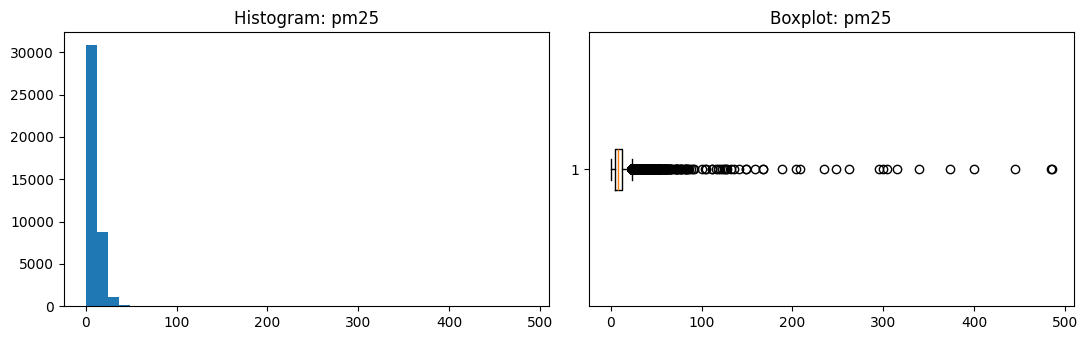

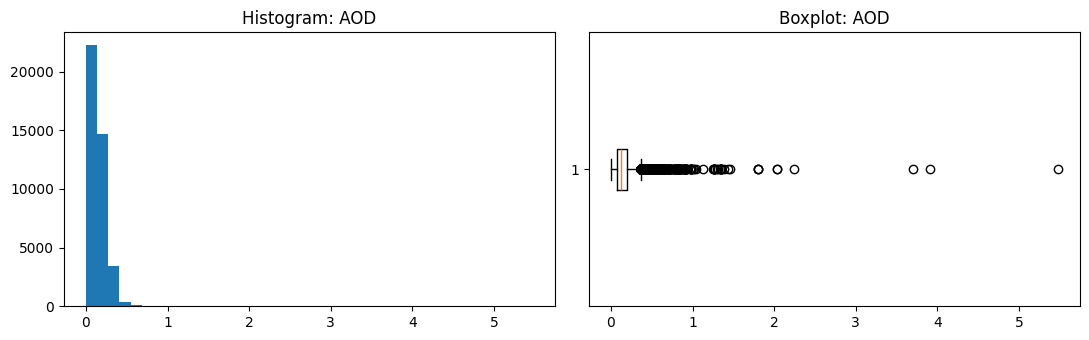

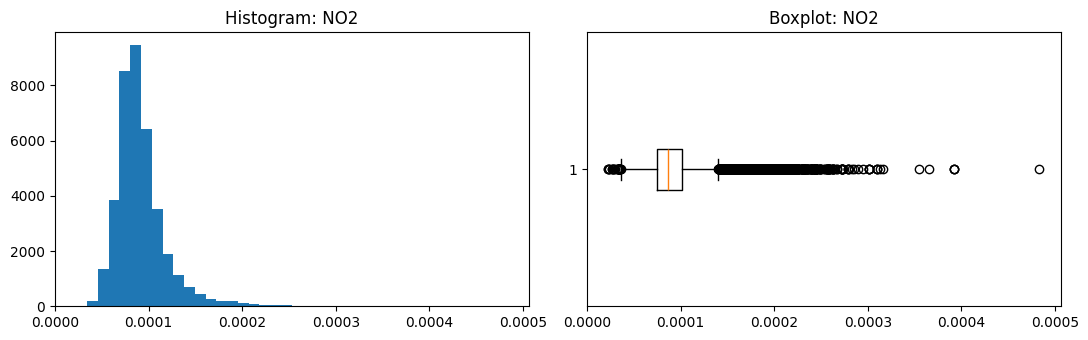

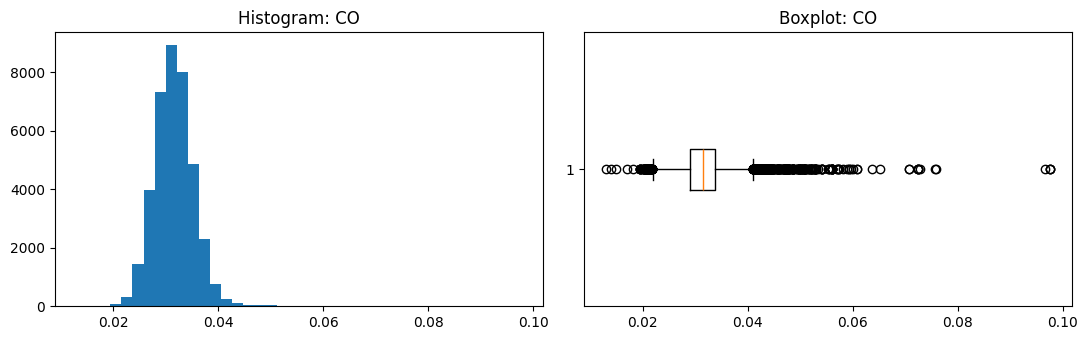

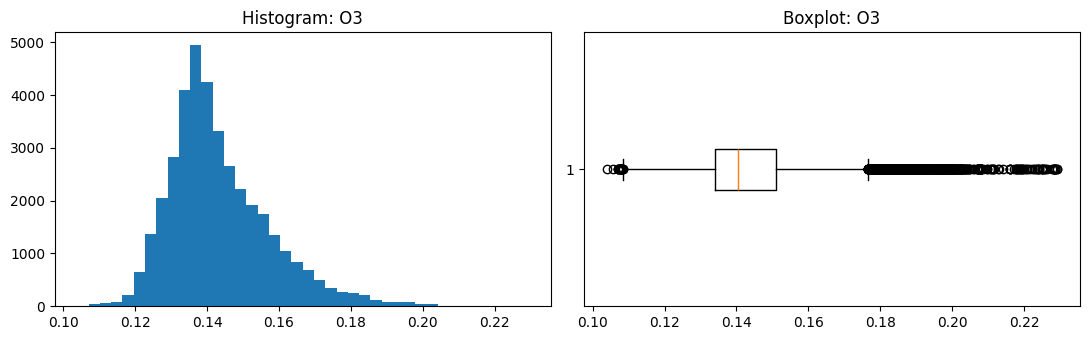

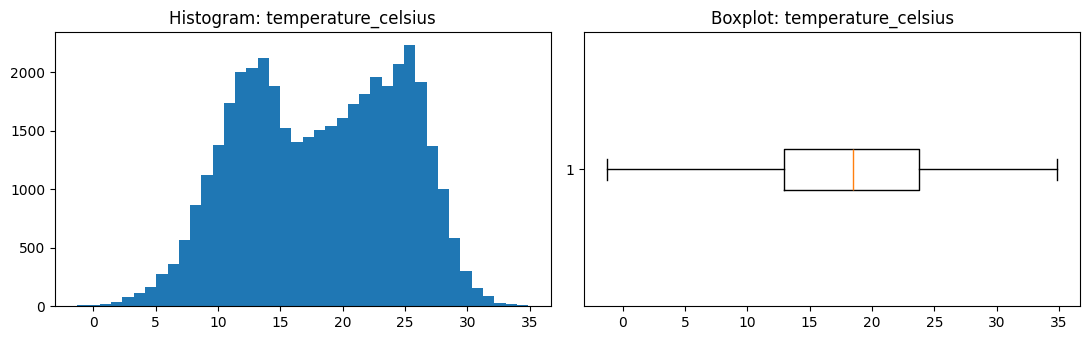

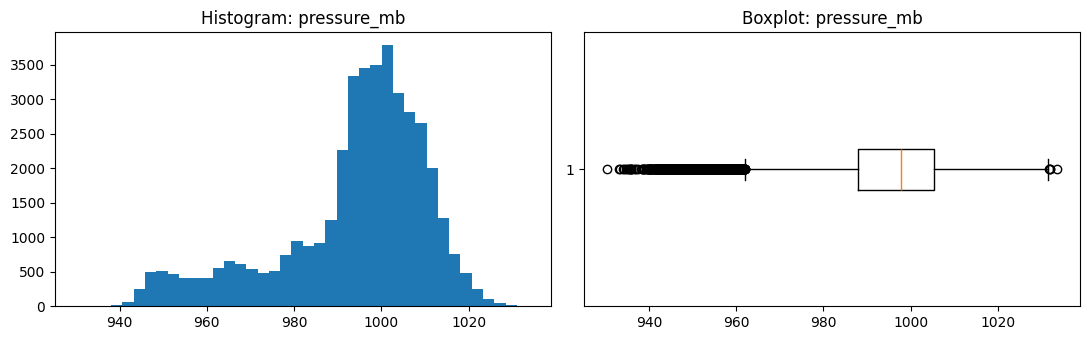

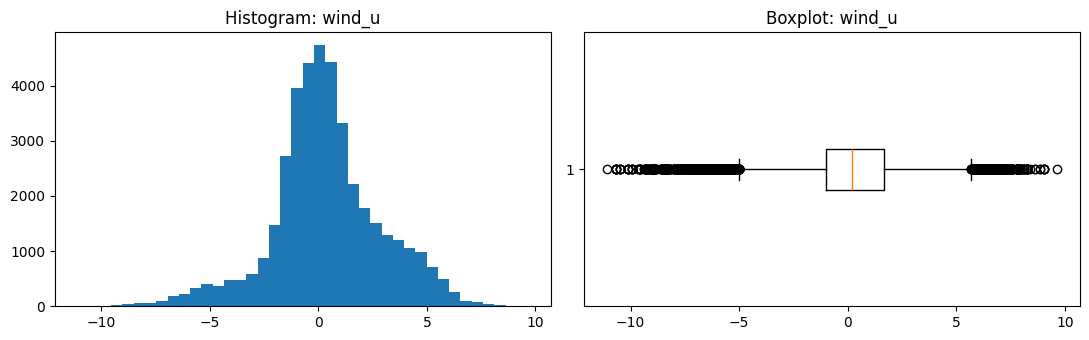

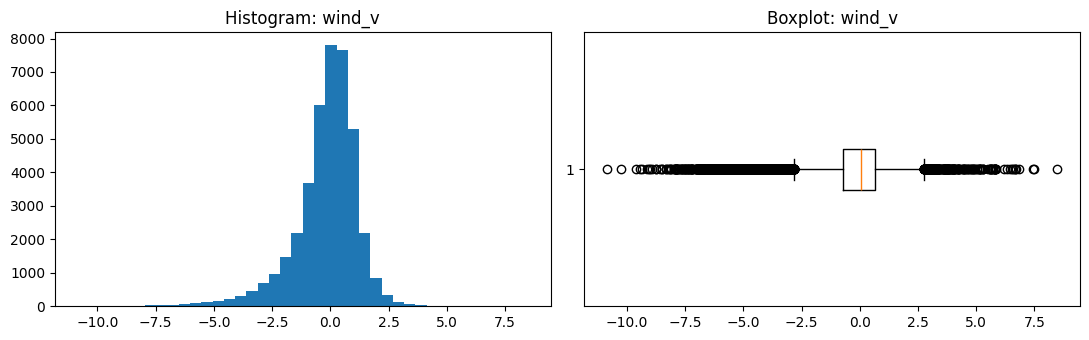

In [12]:
eda_vars = ["pm25","AOD","NO2","CO","O3","temperature_celsius","pressure_mb","wind_u","wind_v"]
for col in eda_vars:
    fig, axes = plt.subplots(1,2,figsize=(11,3.5))
    axes[0].hist(df[col].dropna(),bins=40); axes[0].set_title(f"Histogram: {col}")
    axes[1].boxplot(df[col].dropna(),vert=False); axes[1].set_title(f"Boxplot: {col}")
    plt.tight_layout(); plt.show()

In [13]:
print("PM2.5 > 25:",(df.pm25>25).sum(),f"({(df.pm25>25).mean()*100:.2f}%)")
print("PM2.5 > 50:",(df.pm25>50).sum(),f"({(df.pm25>50).mean()*100:.2f}%)")
seasonal=df.assign(month=df.date.dt.month).groupby("month").agg(
    n_records=("pm25","size"),pm25_median=("pm25","median"),
    pm25_q1=("pm25",lambda x:x.quantile(.25)),pm25_q3=("pm25",lambda x:x.quantile(.75)),
    pct_above_25=("pm25",lambda x:(x>25).mean()*100),
    pct_above_50=("pm25",lambda x:(x>50).mean()*100)).reset_index()
display(seasonal); seasonal.to_csv("PM25_Monthly_Summary.csv",index=False)

PM2.5 > 25: 1223 (2.98%)
PM2.5 > 50: 117 (0.29%)


,month,n_records,pm25_median,pm25_q1,pm25_q3,pct_above_25,pct_above_50
0,1,3032,8.145129,4.336458,13.234375,4.848285,0.395778
1,2,3113,9.250000,5.000000,14.391304,6.617411,0.546097
2,3,2752,7.256875,4.419819,12.000000,3.997093,0.617733
3,4,2998,6.438750,3.943095,9.809375,1.300867,0.266845
4,5,3526,6.872958,4.301250,10.024694,0.822462,0.226886
5,6,4154,7.811962,4.905844,12.000000,1.901781,0.048146
6,7,4288,8.301400,5.049632,11.964664,1.305970,0.163246
7,8,4324,9.362083,6.000000,13.852500,2.636448,0.231267
8,9,3591,7.000000,4.147129,10.103283,1.392370,0.139237
9,10,3043,7.800000,4.689931,11.833333,2.464673,0.098587


In [14]:
eda_corr_vars=["pm25","AOD","NO2","CO","O3","temperature_celsius","pressure_mb","wind_u","wind_v"]
pearson_corr=df[eda_corr_vars].corr(method="pearson")
spearman_corr=df[eda_corr_vars].corr(method="spearman")
display(pearson_corr); display(spearman_corr)
pearson_corr.to_csv("PM25_Pearson_Correlation.csv")
spearman_corr.to_csv("PM25_Spearman_Correlation.csv")

,pm25,AOD,NO2,CO,O3,temperature_celsius,pressure_mb,wind_u,wind_v
pm25,1.000000,0.094209,0.159311,0.041462,-0.087197,-0.006029,0.113291,-0.078638,0.059479
AOD,0.094209,1.000000,-0.061578,0.132956,-0.009698,0.332200,0.017390,-0.247343,0.163810
NO2,0.159311,-0.061578,1.000000,0.099938,-0.094424,-0.055051,0.166248,-0.088724,0.105886
CO,0.041462,0.132956,0.099938,1.000000,0.210167,-0.125935,0.198497,0.032590,-0.074568
O3,-0.087197,-0.009698,-0.094424,0.210167,1.000000,-0.320234,-0.033617,0.161986,-0.119938
temperature_celsius,-0.006029,0.332200,-0.055051,-0.125935,-0.320234,1.000000,-0.062345,-0.179202,0.337792
pressure_mb,0.113291,0.017390,0.166248,0.198497,-0.033617,-0.062345,1.000000,-0.086242,-0.043925
wind_u,-0.078638,-0.247343,-0.088724,0.032590,0.161986,-0.179202,-0.086242,1.000000,-0.218186
wind_v,0.059479,0.163810,0.105886,-0.074568,-0.119938,0.337792,-0.043925,-0.218186,1.000000


,pm25,AOD,NO2,CO,O3,temperature_celsius,pressure_mb,wind_u,wind_v
pm25,1.000000,0.180124,0.246781,0.036306,-0.135110,0.064179,0.167119,-0.163505,0.097199
AOD,0.180124,1.000000,-0.040262,0.032212,0.007004,0.403103,0.020372,-0.367271,0.261469
NO2,0.246781,-0.040262,1.000000,0.105394,-0.056502,0.065175,0.143243,-0.111158,0.135936
CO,0.036306,0.032212,0.105394,1.000000,0.278350,-0.182432,0.182495,0.045265,-0.067794
O3,-0.135110,0.007004,-0.056502,0.278350,1.000000,-0.299398,-0.052827,0.117078,-0.071434
temperature_celsius,0.064179,0.403103,0.065175,-0.182432,-0.299398,1.000000,-0.089540,-0.241746,0.391534
pressure_mb,0.167119,0.020372,0.143243,0.182495,-0.052827,-0.089540,1.000000,-0.110681,-0.074749
wind_u,-0.163505,-0.367271,-0.111158,0.045265,0.117078,-0.241746,-0.110681,1.000000,-0.206915
wind_v,0.097199,0.261469,0.135936,-0.067794,-0.071434,0.391534,-0.074749,-0.206915,1.000000


In [15]:
# Correlate PM2.5 at day t with each predictor at t-k, separately by station.
lead_lag_rows=[]
for variable in ["AOD","NO2","CO","O3","temperature_celsius","pressure_mb","wind_u","wind_v","pm25"]:
    for lag in [0,1,2,3,7]:
        station_corrs=[]; total_pairs=0
        for station_id,group in df.groupby("id"):
            indexed=group.set_index("date")
            target=indexed["pm25"].asfreq("D")
            past=indexed[variable].asfreq("D").shift(lag)
            pairs=pd.concat([target.rename("target"),past.rename("past")],axis=1).dropna()
            if len(pairs)>=10 and pairs.target.nunique()>1 and pairs.past.nunique()>1:
                station_corrs.append(pairs.target.corr(pairs.past)); total_pairs+=len(pairs)
        lead_lag_rows.append({"predictor":variable,"lag_days":lag,
            "median_station_pearson_r":np.median(station_corrs) if station_corrs else np.nan,
            "n_stations":len(station_corrs),"n_valid_pairs":total_pairs})
lead_lag=pd.DataFrame(lead_lag_rows); display(lead_lag)
lead_lag.to_csv("PM25_LeadLag_Correlations.csv",index=False)

,predictor,lag_days,median_station_pearson_r,n_stations,n_valid_pairs
0,AOD,0,0.180096,93,40975
1,AOD,1,0.133854,93,27256
2,AOD,2,0.047391,93,25408
3,AOD,3,0.041485,93,25178
4,AOD,7,-0.020777,91,24365
5,NO2,0,0.237718,93,38568
6,NO2,1,0.240655,93,25599
7,NO2,2,0.150934,93,23995
8,NO2,3,0.087718,93,23828
9,NO2,7,0.089208,91,23034


**Interpretation:** lag 0 is same-day exploratory association; lag 1 and above use past calendar days. Missing days remain missing and are not bridged. Correlation does not establish causation.

In [16]:

# STEP 6 — Define the final independent test period

import pandas as pd

# The dataset ends on 6 April 2026.
test_start = pd.Timestamp("2025-04-07")
test_end = pd.Timestamp("2026-04-06")

# Make sure dates have the correct format
model_data["date"] = pd.to_datetime(model_data["date"])

# Development data: everything before the final test period
development_data = model_data[
    model_data["date"] < test_start
].copy().reset_index(drop=True)

# Final test data: one complete year
final_test_data = model_data[
    model_data["date"].between(test_start, test_end)
].copy().reset_index(drop=True)

# Check the separation
assert development_data["date"].max() < test_start
assert final_test_data["date"].min() >= test_start
assert final_test_data["date"].max() <= test_end
assert len(development_data) + len(final_test_data) == len(model_data)

print("DEVELOPMENT DATA")
print("Rows:", len(development_data))
print("First date:", development_data["date"].min())
print("Last date:", development_data["date"].max())
print("Stations:", development_data["id"].nunique())

print("\nFINAL TEST DATA")
print("Rows:", len(final_test_data))
print("First date:", final_test_data["date"].min())
print("Last date:", final_test_data["date"].max())
print("Stations:", final_test_data["id"].nunique())

print("\nCHECKS")
print("Development/Test overlap:",
      len(set(development_data["date"]) & set(final_test_data["date"])))
print("Total rows:", len(model_data))
print("Rows after splitting:",
      len(development_data) + len(final_test_data))


DEVELOPMENT DATA
Rows: 21586
First date: 2016-12-03 00:00:00
Last date: 2025-04-06 00:00:00
Stations: 76

FINAL TEST DATA
Rows: 5673
First date: 2025-04-07 00:00:00
Last date: 2026-04-06 00:00:00
Stations: 55

CHECKS
Development/Test overlap: 0
Total rows: 27259
Rows after splitting: 27259


Cellule 14 — Temporal Cross-Validation


In [17]:
from sklearn.model_selection import TimeSeriesSplit
import numpy as np
import pandas as pd

# Use development data only
dev = development_data.copy()

# Create a continuous daily calendar
calendar_dates = pd.date_range(
    start=dev["date"].min(),
    end=dev["date"].max(),
    freq="D"
)

# Five chronological folds, with one calendar day gap
tscv = TimeSeriesSplit(n_splits=5, gap=1)

temporal_folds = {}
temporal_summary = []

for fold, (train_idx, valid_idx) in enumerate(
    tscv.split(calendar_dates), start=1
):

    train_dates = calendar_dates[train_idx]
    valid_dates = calendar_dates[valid_idx]

    train_rows = np.flatnonzero(
        dev["date"].isin(train_dates).to_numpy()
    )

    valid_rows = np.flatnonzero(
        dev["date"].isin(valid_dates).to_numpy()
    )

    temporal_folds[f"train_{fold}"] = train_rows
    temporal_folds[f"valid_{fold}"] = valid_rows

    temporal_summary.append({
        "fold": fold,
        "train_rows": len(train_rows),
        "validation_rows": len(valid_rows),
        "train_start": dev.iloc[train_rows]["date"].min(),
        "train_end": dev.iloc[train_rows]["date"].max(),
        "validation_start": dev.iloc[valid_rows]["date"].min(),
        "validation_end": dev.iloc[valid_rows]["date"].max()
    })

temporal_summary = pd.DataFrame(temporal_summary)

display(temporal_summary)

# Save fold indices for later reuse
np.savez_compressed(
    "PM25_Temporal_Folds.npz",
    **temporal_folds
)

print("Temporal folds saved successfully.")

,fold,train_rows,validation_rows,train_start,train_end,validation_start,validation_end
0,1,1641,1177,2016-12-03,2018-01-17,2018-06-24,2019-09-01
1,2,2818,2347,2016-12-03,2019-09-01,2020-01-07,2021-01-31
2,3,5165,4418,2016-12-03,2021-01-31,2021-02-06,2022-06-25
3,4,9583,4219,2016-12-03,2022-06-25,2022-06-28,2023-11-16
4,5,13798,7784,2016-12-03,2023-11-15,2023-11-17,2025-04-06


Temporal folds saved successfully.


Cellule 15 — Spatial Cross-Validation


In [18]:
from sklearn.model_selection import GroupKFold
import numpy as np
import pandas as pd

dev = development_data.copy()

groups = dev["id"].to_numpy()
X_placeholder = np.zeros((len(dev), 1))

gkf = GroupKFold(n_splits=5)

spatial_folds = {}
spatial_summary = []

for fold, (train_idx, valid_idx) in enumerate(
    gkf.split(X_placeholder, groups=groups), start=1
):

    train_stations = set(groups[train_idx])
    valid_stations = set(groups[valid_idx])

    shared_stations = train_stations.intersection(valid_stations)

    assert len(shared_stations) == 0

    spatial_folds[f"train_{fold}"] = train_idx
    spatial_folds[f"valid_{fold}"] = valid_idx

    spatial_summary.append({
        "fold": fold,
        "train_rows": len(train_idx),
        "validation_rows": len(valid_idx),
        "train_stations": len(train_stations),
        "validation_stations": len(valid_stations),
        "shared_stations": len(shared_stations)
    })

spatial_summary = pd.DataFrame(spatial_summary)

display(spatial_summary)

# Save fold indices for later reuse
np.savez_compressed(
    "PM25_Spatial_Folds.npz",
    **spatial_folds
)

print("Spatial folds saved successfully.")

,fold,train_rows,validation_rows,train_stations,validation_stations,shared_stations
0,1,17278,4308,61,15,0
1,2,17252,4334,61,15,0
2,3,17264,4322,61,15,0
3,4,17275,4311,60,16,0
4,5,17275,4311,61,15,0


Spatial folds saved successfully.


3. Vérification supplémentaire des stations

In [19]:
development_stations = set(development_data["id"])
test_stations = set(final_test_data["id"])

print("Stations in development:",
      len(development_stations))

print("Stations in final test:",
      len(test_stations))

print("Stations common to both periods:",
      len(development_stations.intersection(test_stations)))

print("Stations only in final test:",
      len(test_stations - development_stations))

Stations in development: 76
Stations in final test: 55
Stations common to both periods: 37
Stations only in final test: 18


In [20]:

import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit

# Use development data only
dev = development_data.copy()
dev["date"] = pd.to_datetime(dev["date"])

# Calendar covering the development period only
calendar_dates = pd.date_range(
    start=dev["date"].min(),
    end=dev["date"].max(),
    freq="D"
)

# Recreate the same temporal folds
tscv_check = TimeSeriesSplit(n_splits=5, gap=1)

validation_results = []

for fold, (train_idx, valid_idx) in enumerate(
    tscv_check.split(calendar_dates), start=1
):

    train_dates = calendar_dates[train_idx]
    valid_dates = calendar_dates[valid_idx]

    # Calendar boundaries
    last_train_calendar = train_dates.max()
    first_valid_calendar = valid_dates.min()

    # Check the number of calendar days between boundaries
    calendar_difference = (
        first_valid_calendar - last_train_calendar
    ).days

    # Get actual rows belonging to each period
    train_rows = dev[dev["date"].isin(train_dates)]
    valid_rows = dev[dev["date"].isin(valid_dates)]

    # Actual observed date boundaries
    last_train_observed = train_rows["date"].max()
    first_valid_observed = valid_rows["date"].min()

    # Check chronological order
    chronological_order = last_train_calendar < first_valid_calendar

    # One complete calendar day must be excluded
    one_day_gap = calendar_difference >= 2

    # Check no shared dates between train and validation
    no_date_overlap = set(train_dates).isdisjoint(set(valid_dates))

    validation_results.append({
        "Fold": fold,
        "Last training calendar date": last_train_calendar.date(),
        "First validation calendar date": first_valid_calendar.date(),
        "Calendar difference (days)": calendar_difference,
        "Last observed training date": last_train_observed.date(),
        "First observed validation date": first_valid_observed.date(),
        "Chronological order": chronological_order,
        "One-day gap": one_day_gap,
        "No date overlap": no_date_overlap
    })

validation_check = pd.DataFrame(validation_results)

display(validation_check)

print("All chronological checks:",
      validation_check["Chronological order"].all())

print("All one-day gap checks:",
      validation_check["One-day gap"].all())

print("All no-overlap checks:",
      validation_check["No date overlap"].all())


,Fold,Last training calendar date,First validation calendar date,Calendar difference (days),Last observed training date,First observed validation date,Chronological order,One-day gap,No date overlap
0,1,2018-04-27,2018-04-29,2,2018-01-17,2018-06-24,True,True,True
1,2,2019-09-16,2019-09-18,2,2019-09-01,2020-01-07,True,True,True
2,3,2021-02-04,2021-02-06,2,2021-01-31,2021-02-06,True,True,True
3,4,2022-06-26,2022-06-28,2,2022-06-25,2022-06-28,True,True,True
4,5,2023-11-15,2023-11-17,2,2023-11-15,2023-11-17,True,True,True


All chronological checks: True
All one-day gap checks: True
All no-overlap checks: True


In [21]:

# Check that the final test period is outside all temporal folds

test_start = final_test_data["date"].min()
test_end = final_test_data["date"].max()

all_temporal_train_dates = set()
all_temporal_valid_dates = set()

for train_idx, valid_idx in tscv_check.split(calendar_dates):

    train_dates = calendar_dates[train_idx]
    valid_dates = calendar_dates[valid_idx]

    all_temporal_train_dates.update(train_dates)
    all_temporal_valid_dates.update(valid_dates)

test_dates = set(pd.to_datetime(final_test_data["date"]))

train_test_overlap = all_temporal_train_dates.intersection(test_dates)
valid_test_overlap = all_temporal_valid_dates.intersection(test_dates)

print("Final test start:", test_start)
print("Final test end:", test_end)

print("Training/Test date overlap:", len(train_test_overlap))
print("Validation/Test date overlap:", len(valid_test_overlap))

print("Final test excluded from all temporal folds:",
      len(train_test_overlap) == 0 and len(valid_test_overlap) == 0)


Final test start: 2025-04-07 00:00:00
Final test end: 2026-04-06 00:00:00
Training/Test date overlap: 0
Validation/Test date overlap: 0
Final test excluded from all temporal folds: True


In [22]:

# Save validation results
temporal_summary.to_csv(
    "PM25_Temporal_CV_Summary.csv", index=False
)

spatial_summary.to_csv(
    "PM25_Spatial_CV_Summary.csv", index=False
)

validation_check.to_csv(
    "PM25_Temporal_Validation_Checks.csv", index=False
)

# Download important validation files
from google.colab import files

for filename in [
    "PM25_Temporal_Folds.npz",
    "PM25_Spatial_Folds.npz",
    "PM25_Temporal_CV_Summary.csv",
    "PM25_Spatial_CV_Summary.csv",
    "PM25_Temporal_Validation_Checks.csv"
]:
    files.download(filename)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
import numpy as np, pandas as pd, warnings
from statsmodels.tsa.stattools import pacf, adfuller

variables = ["pm25", "AOD", "NO2", "CO", "O3",
             "temperature_celsius", "pressure_mb", "wind_u", "wind_v"]

def longest_run(s):
    """Longest uninterrupted daily stretch (no gaps, no NaN) of a series."""
    mask = s.notna().to_numpy()
    best_start = best_len = run_start = run_len = 0
    for i, ok in enumerate(mask):
        if ok:
            if run_len == 0:
                run_start = i
            run_len += 1
            if run_len > best_len:
                best_start, best_len = run_start, run_len
        else:
            run_len = 0
    return s.iloc[best_start:best_start + best_len].to_numpy(dtype=float)

def significant_lags(x, max_lag=14):
    """Number of PACF lags that are significant before the first non-significant one."""
    nlags = min(max_lag, len(x) // 2 - 1)
    if nlags < 1:
        return np.nan
    vals = pacf(x, nlags=nlags, method="ywm")[1:]
    bound = 1.96 / np.sqrt(len(x))
    count = 0
    for v in vals:
        if abs(v) > bound:
            count += 1
        else:
            break
    return count

rows = []
for var in variables:
    acf1_l, acf24_l, pacf1_l, adf_l, nlag_l = [], [], [], [], []
    for sid, g in df.groupby("id"):
        s = g.sort_values("date").set_index("date")[var].asfreq("D")
        if s.notna().sum() > 2:
            a = s.autocorr(1)
            if pd.notna(a):
                acf1_l.append(a)
        if s.notna().sum() > 24:
            a24 = s.autocorr(24)
            if pd.notna(a24):
                acf24_l.append(a24)

        x = longest_run(s)
        if len(x) >= 30 and np.var(x) > 0:
            try:
                pacf1_l.append(pacf(x, nlags=1, method="ywm")[1])
            except Exception:
                pass
            try:
                adf_l.append(adfuller(x, autolag="AIC")[1])
            except Exception:
                pass
            try:
                n = significant_lags(x)
                if pd.notna(n):
                    nlag_l.append(n)
            except Exception:
                pass

    rows.append({
        "model_id": "gradient_boosting_pm25",
        "model_group": "G7",
        "variable": var,
        "acf_lag1": np.median(acf1_l) if acf1_l else np.nan,
        "acf_lag24": np.median(acf24_l) if acf24_l else np.nan,
        "pacf_lag1": np.median(pacf1_l) if pacf1_l else np.nan,
        "n_lags_recommended": np.median(nlag_l) if nlag_l else np.nan,
        "adf_p": np.median(adf_l) if adf_l else np.nan,
        "notes": (f"Median across stations. ACF1: {len(acf1_l)}, ACF24: {len(acf24_l)} stations; "
                  f"PACF/ADF/lags: {len(adf_l)} stations with >=30 consecutive daily obs. "
                  "ACF lag24 represents 24 calendar days.")
    })

part_p4 = pd.DataFrame(rows)
display(part_p4)
part_p4.to_csv("Exploratory_Data_part_P4.csv", index=False, encoding="utf-8")
print("Exploratory_Data_part_P4.csv saved successfully.")

/tmp/ipykernel_54479/613021614.py:58: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_l.append(adfuller(x, autolag="AIC")[1])
/tmp/ipykernel_54479/613021614.py:58: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_l.append(adfuller(x, autolag="AIC")[1])
/tmp/ipykernel_54479/613021614.py:58: FutureWarning: adfuller currently returns a plain tuple whose length depends on 

,model_id,model_group,variable,acf_lag1,acf_lag24,pacf_lag1,n_lags_recommended,adf_p,notes
0,gradient_boosting_pm25,G7,pm25,0.655459,0.050449,0.564207,1.0,0.161533,"Median across stations. ACF1: 94, ACF24: 91 st..."
1,gradient_boosting_pm25,G7,AOD,0.427284,0.149511,0.140497,0.0,0.004090,"Median across stations. ACF1: 94, ACF24: 91 st..."
2,gradient_boosting_pm25,G7,NO2,0.358365,0.027705,0.153852,0.0,0.000098,"Median across stations. ACF1: 94, ACF24: 91 st..."
3,gradient_boosting_pm25,G7,CO,0.488622,0.113752,0.251436,0.0,0.000124,"Median across stations. ACF1: 94, ACF24: 91 st..."
4,gradient_boosting_pm25,G7,O3,0.786121,0.492996,0.644337,1.0,0.026569,"Median across stations. ACF1: 94, ACF24: 91 st..."
5,gradient_boosting_pm25,G7,temperature_celsius,0.979711,0.823218,0.714404,1.0,0.258848,"Median across stations. ACF1: 94, ACF24: 91 st..."
6,gradient_boosting_pm25,G7,pressure_mb,0.855791,0.185441,0.706983,2.0,0.359606,"Median across stations. ACF1: 94, ACF24: 91 st..."
7,gradient_boosting_pm25,G7,wind_u,0.691165,0.152186,0.398913,1.0,0.020537,"Median across stations. ACF1: 94, ACF24: 91 st..."
8,gradient_boosting_pm25,G7,wind_v,0.564974,0.162786,0.464880,1.0,0.039929,"Median across stations. ACF1: 94, ACF24: 91 st..."


Exploratory_Data_part_P4.csv saved successfully.


In [ ]:
import os, shutil
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf, pacf

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.3})

daily = df.groupby("date")["pm25"].mean()
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily.index, daily.values, lw=0.6, alpha=0.6, label="Daily mean (all stations)")
ax.plot(daily.index, daily.rolling(30, min_periods=5).mean(), lw=2, label="30-day rolling mean")
ax.set_title("Daily mean PM2.5 over time")
ax.set_xlabel("Date"); ax.set_ylabel("PM2.5 (µg/m³)"); ax.legend()
fig.tight_layout(); fig.savefig("figures/fig1_daily_mean_pm25.png"); plt.close(fig)

def longest_run(s):
    mask = s.notna().to_numpy()
    best_start = best_len = run_start = run_len = 0
    for i, ok in enumerate(mask):
        if ok:
            if run_len == 0: run_start = i
            run_len += 1
            if run_len > best_len: best_start, best_len = run_start, run_len
        else:
            run_len = 0
    return s.iloc[best_start:best_start + best_len].to_numpy(dtype=float)

runs = {}
for sid, g in df.groupby("id"):
    s = g.sort_values("date").set_index("date")["pm25"].asfreq("D")
    runs[sid] = longest_run(s)
top = sorted(runs, key=lambda k: len(runs[k]), reverse=True)[:3]

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for j, sid in enumerate(top):
    x = runs[sid]; n = len(x); nl = 14
    a = acf(x, nlags=nl); p = pacf(x, nlags=nl, method="ywm"); b = 1.96 / np.sqrt(n)
    for row, vals, name in [(0, a, "ACF"), (1, p, "PACF")]:
        ax = axes[row, j]
        ax.bar(range(nl + 1), vals, width=0.6)
        ax.axhline(b, ls="--", c="red", lw=1); ax.axhline(-b, ls="--", c="red", lw=1)
        ax.set_xticks(range(0, nl + 1, 2))
        ax.set_title(f"{name} - station {sid} ({n} consecutive days)")
        ax.set_xlabel("Lag (days)")
fig.tight_layout(); fig.savefig("figures/fig2_acf_pacf_stations.png"); plt.close(fig)

m = df.assign(month=df["date"].dt.month).groupby("month")["pm25"]
med, q1, q3 = m.median(), m.quantile(0.25), m.quantile(0.75)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(med.index, med.values, marker="o", label="Median")
ax.fill_between(med.index, q1.values, q3.values, alpha=0.25, label="Q1-Q3")
ax.set_xticks(range(1, 13)); ax.set_title("Seasonal pattern of PM2.5 (by month, all years)")
ax.set_xlabel("Month"); ax.set_ylabel("PM2.5 (µg/m³)"); ax.legend()
fig.tight_layout(); fig.savefig("figures/fig3_monthly_seasonality.png"); plt.close(fig)

years = sorted(df["date"].dt.year.unique())
data = [df.loc[df["date"].dt.year == y, "pm25"].values for y in years]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.boxplot(data, showfliers=False)
ax.set_xticklabels([f"{y}\n(n={len(d)})" for y, d in zip(years, data)])
ax.set_title("PM2.5 distribution by year (outliers hidden) - drift check")
ax.set_ylabel("PM2.5 (µg/m³)")
fig.tight_layout(); fig.savefig("figures/fig4_drift_by_year.png"); plt.close(fig)

fig, ax = plt.subplots(figsize=(10, 5))
for pred, g in lead_lag.groupby("predictor"):
    g = g.sort_values("lag_days")
    style = "--" if pred == "pm25" else "-"
    ax.plot(g["lag_days"], g["median_station_pearson_r"], marker="o", ls=style, label=pred)
ax.axhline(0, c="black", lw=0.8)
ax.set_xticks([0, 1, 2, 3, 7])
ax.set_title("Lead-lag: correlation of PM2.5 (day t) with each variable at day t-lag")
ax.set_xlabel("Lag (days)"); ax.set_ylabel("Median station Pearson r")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig("figures/fig5_lead_lag.png"); plt.close(fig)

shutil.make_archive("figures", "zip", "figures")
print("Done. Files:", sorted(os.listdir("figures")))

Done. Files: ['fig1_daily_mean_pm25.png', 'fig2_acf_pacf_stations.png', 'fig3_monthly_seasonality.png', 'fig4_drift_by_year.png', 'fig5_lead_lag.png']
